<a href="https://colab.research.google.com/github/eduardozurek/ia/blob/main/_008_redes_neuronales_artificiales/05_Aproximaci%C3%B3n_de_Funciones_con_Redes_de_Base_Radial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aproximación de funciones con redes de base radial (RBF)

**Conversión del ejemplo de Octave a Python.** El cuaderno construye una aproximación de una función no lineal mediante siete funciones gaussianas y ajusta los pesos de salida por mínimos cuadrados.

**Objetivos:** visualizar las muestras, interpretar las gaussianas, construir la matriz de diseño, deducir el ajuste de pesos y medir el error de aproximación.

## 1. Función de referencia

La función que deseamos aproximar es

$$
f(x)=\cos(0.7\cdot 3\pi x)+\sin(0.3\cdot 3\pi x),\qquad -1\le x\le 1.
$$

Evaluamos la función en 501 puntos para disponer de una curva de referencia. Después tomamos **41 muestras aleatorias** para entrenar el modelo. La semilla permite reproducir el experimento.

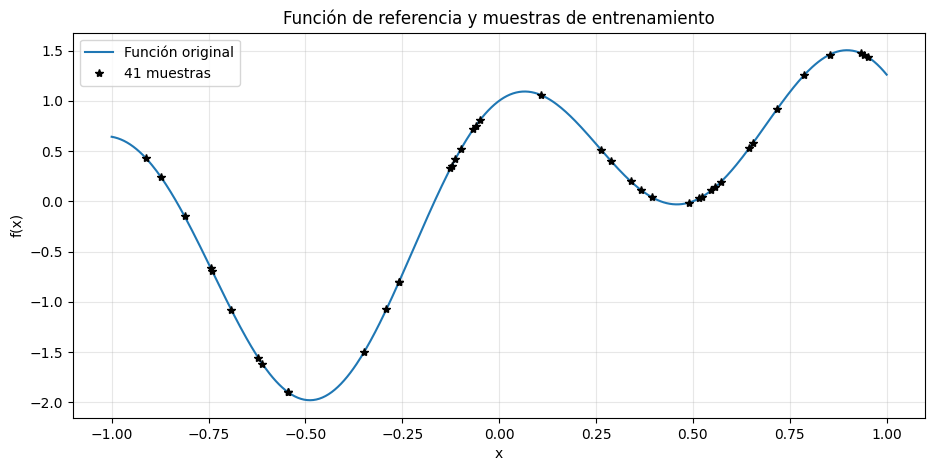

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
n = 500
xo = np.linspace(-1, 1, n + 1)

def f(x):
    return np.cos(0.7 * x * 3 * np.pi) + np.sin(0.3 * x * 3 * np.pi)

yo = f(xo)
m = 41
x = rng.uniform(-1, 1, size=m)
y = f(x)

plt.figure(figsize=(11, 5))
plt.plot(xo, yo, label="Función original")
plt.plot(x, y, "*k", label="41 muestras")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Función de referencia y muestras de entrenamiento")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 2. Funciones gaussianas de base radial

Cada neurona oculta calcula una función gaussiana centrada en $c_k$:

$$
g_k(x)=\exp\left(-\frac{(x-c_k)^2}{\sigma^2}\right).
$$

Usamos $c=7$ centros uniformemente distribuidos en $[-1,1]$:

$$
c_k=-1+\frac{2(k-1)}{c-1},\quad k=1,\ldots,c.
$$

El parámetro $\sigma$ se fija como el **doble de la separación promedio** entre centros vecinos. En este código `std1` es el parámetro $\sigma$ de la fórmula utilizada; **no** corresponde a la desviación estándar de la parametrización gaussiana convencional $\exp[-(x-c)^2/(2s^2)]$.

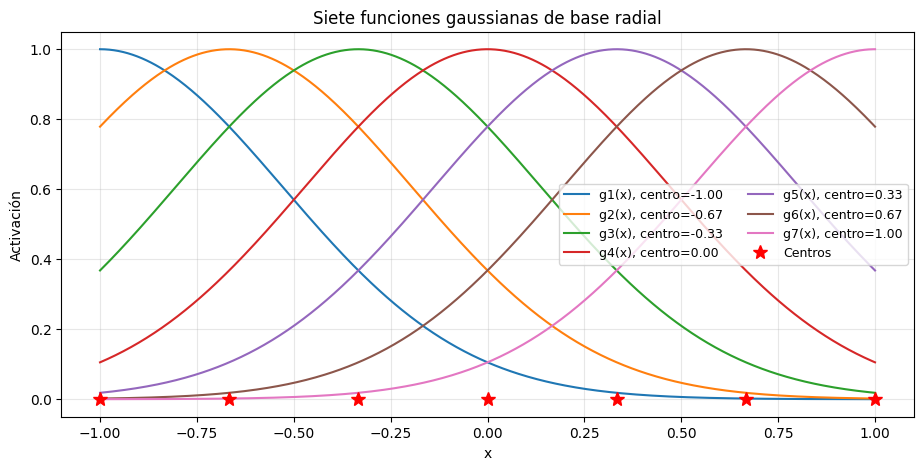

Centros: [-1.         -0.66666667 -0.33333333  0.          0.33333333  0.66666667
  1.        ]
Parámetro sigma: 0.666667


In [2]:
c = 7
cent1 = np.linspace(-1, 1, c)
std1 = 2 * np.mean(np.diff(cent1))

# Cada columna corresponde a una gaussiana y cada fila a un punto.
G_grid = np.exp(-((xo[:, None] - cent1[None, :]) ** 2) / std1**2)

plt.figure(figsize=(11, 5))
for k in range(c):
    plt.plot(xo, G_grid[:, k], label=f"g{k+1}(x), centro={cent1[k]:.2f}")
plt.plot(cent1, np.zeros_like(cent1), "*r", markersize=10, label="Centros")
plt.xlabel("x")
plt.ylabel("Activación")
plt.title("Siete funciones gaussianas de base radial")
plt.grid(alpha=0.3)
plt.legend(ncol=2, fontsize=9)
plt.show()
print(f"Centros: {cent1}")
print(f"Parámetro sigma: {std1:.6f}")

## 3. Modelo RBF y dimensiones matriciales

La salida del modelo es una **combinación lineal de las activaciones gaussianas**:

$$
\hat y(x)=g_1(x)w_1+g_2(x)w_2+\cdots+g_7(x)w_7
=\sum_{k=1}^{7}g_k(x)w_k.
$$

Para $m=41$ observaciones y $c=7$ gaussianas, definimos

$$
\mathbf M=\begin{bmatrix}
g_1(x_1)&\cdots&g_7(x_1)\\
\vdots&\ddots&\vdots\\
g_1(x_{41})&\cdots&g_7(x_{41})
\end{bmatrix}\in\mathbb R^{41\times7},
\qquad
\mathbf w\in\mathbb R^{7\times1},\quad
\mathbf y\in\mathbb R^{41\times1}.
$$

Por tanto,

$$\boxed{\hat{\mathbf y}=\mathbf M\mathbf w}$$

La matriz `M` de Python tiene una fila por muestra y una columna por gaussiana. En el código original de Octave, la matriz se construía inicialmente con la orientación opuesta y después se transponía.

## 4. Deducción correcta de los pesos mediante mínimos cuadrados

Como hay más muestras que gaussianas ($41>7$), generalmente no existe un vector $\mathbf w$ que satisfaga exactamente $\mathbf M\mathbf w=\mathbf y$. Buscamos el vector que minimice

$$
J(\mathbf w)=\|\mathbf M\mathbf w-\mathbf y\|_2^2.
$$

Igualando a cero el gradiente:

$$
\nabla_{\mathbf w}J=2\mathbf M^T(\mathbf M\mathbf w-\mathbf y)=\mathbf0.
$$

Obtenemos las **ecuaciones normales**:

$$
\mathbf M^T\mathbf M\mathbf w=\mathbf M^T\mathbf y.
$$

Si $\mathbf M^T\mathbf M$ es invertible, la solución puede escribirse como

$$
\boxed{\mathbf w=(\mathbf M^T\mathbf M)^{-1}\mathbf M^T\mathbf y}.
$$

Esta es la fórmula que calcula el script original de Octave después de transponer su matriz `M`. En Python preferimos `np.linalg.lstsq`, que evita formar explícitamente la inversa y ofrece mayor estabilidad numérica.

In [3]:
# Matriz de diseño: 41 filas (muestras) x 7 columnas (gaussianas)
M = np.exp(-((x[:, None] - cent1[None, :]) ** 2) / std1**2)

w, residuos, rango, valores_singulares = np.linalg.lstsq(M, y, rcond=None)

print("Dimensiones de M:", M.shape)
print("Dimensiones de w:", w.shape)
print("Rango de M:", rango)
print("Pesos:")
for k, wk in enumerate(w, start=1):
    print(f"  w{k} = {wk:+.6f}")

Dimensiones de M: (41, 7)
Dimensiones de w: (7,)
Rango de M: 7
Pesos:
  w1 = -11.671050
  w2 = +42.336407
  w3 = -79.695611
  w4 = +95.790679
  w5 = -80.729446
  w6 = +47.104615
  w7 = -14.358961


## 5. Reconstrucción y evaluación

La aproximación sobre la malla completa se calcula multiplicando la matriz de activaciones por el vector de pesos:

$$
\hat{\mathbf y}_{\mathrm{malla}}=\mathbf G_{\mathrm{malla}}\mathbf w.
$$

El **error cuadrático medio (MSE)** en la malla es

$$
\mathrm{MSE}=\frac{1}{N}\sum_{i=1}^{N}(y_i-\hat y_i)^2,
\qquad N=501.
$$

También calculamos el MSE en las 41 muestras de entrenamiento para distinguir el ajuste sobre las observaciones del error sobre toda la función de referencia.

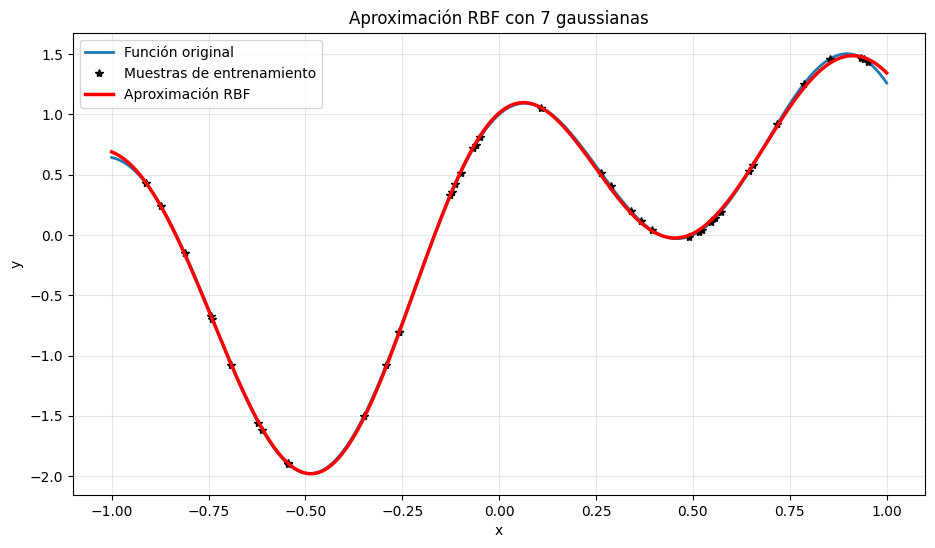

MSE en entrenamiento: 0.00017869
MSE sobre la malla:  0.00028639


In [4]:
y1 = G_grid @ w
yp_train = M @ w
mse_malla = np.mean((yo - y1) ** 2)
mse_entrenamiento = np.mean((y - yp_train) ** 2)

plt.figure(figsize=(11, 6))
plt.plot(xo, yo, label="Función original", linewidth=2)
plt.plot(x, y, "*k", label="Muestras de entrenamiento")
plt.plot(xo, y1, "r", linewidth=2.5, label="Aproximación RBF")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Aproximación RBF con 7 gaussianas")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

print(f"MSE en entrenamiento: {mse_entrenamiento:.8f}")
print(f"MSE sobre la malla:  {mse_malla:.8f}")

## 6. Interpretación de los resultados

- Los **centros** determinan dónde se activan más intensamente las gaussianas.
- El parámetro $\sigma$ controla la anchura y el solapamiento de las funciones de base.
- Los **pesos** pueden ser positivos o negativos; la salida no es una probabilidad, sino una combinación lineal de bases.
- Los pesos se ajustan a las 41 muestras, mientras que la comparación con los 501 valores de la función original permite examinar la aproximación en todo el intervalo.
- Cambiar el número de gaussianas, sus centros o su dispersión puede modificar tanto el error como la capacidad de generalización.

**Experimento propuesto:** cambia `c` a 3, 5, 10 y 15; ejecuta nuevamente las celdas a partir de la sección 2 y compara el MSE de la malla.